# Comparing all our models

In this notebook I compare all the models our team built and pick the one we deploy.

Each of us evaluated our own model in our own notebook, in a different Colab session, and the numbers in our README were copied by hand. So here I load the **saved model files** from the repo, score the same validation and test data, and pass everything through the same `evaluate()` from `evaluate.py`. This way:

- I check that every saved model actually loads and works, because the deployment uses the file, not the notebook
- all models are judged on the same data, with the same threshold rule and the same metrics, in one run
- the model we deploy is chosen from one table that everyone can check

I don't compute any threshold myself: `evaluate()` takes the 99th percentile of each model's benign validation scores, the same rule for everyone.

In [1]:
import os
if not os.path.exists("iomt-anomaly-detection"):
    !git clone -q https://github.com/JanaAlzobidi/iomt-anomaly-detection.git
else:
    !git -C iomt-anomaly-detection pull -q     # get the latest uploads

import io, json, sys, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import keras

REPO = "iomt-anomaly-detection"
DATA_DIR = f"{REPO}/data"
MODELS_DIR = f"{REPO}/models"
sys.path.insert(0, REPO)
from evaluate import load_data, reconstruction_errors, evaluate

SEED = 42
keras.utils.set_random_seed(SEED)

X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)

# the attacks that PCA and our autoencoders struggle with the most
HARD_ATTACKS = ["ARP Spoofing", "MQTT Malformed Data", "Recon VulScan", "Recon PingSweep"]

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


## 1. Which files are on GitHub?

Before comparing anything, I check that every model file is in the repo. The metadata files (threshold and feature order) are only needed for deployment, not for the comparison, because `evaluate()` computes the threshold again anyway.

In [2]:
FILES = {
    "Vanilla AE": ["dense_ae/vanilla_ae.keras", "dense_ae/vanilla_ae_metadata.json"],
    "Denoising AE": ["denoising_ae/denoising_ae.keras"],
    "Sparse AE": ["sparse_ae/sparse_ae.keras", "sparse_ae/sparse_ae_metadata.json"],
    "AE + Isolation Forest": ["ae_isoforest/ae_isoforest.keras", "ae_isoforest/isolation_forest.pkl"],
}

file_check = pd.DataFrame([
    {"model": name, "file": path, "on GitHub": os.path.exists(f"{MODELS_DIR}/{path}")}
    for name, paths in FILES.items() for path in paths
])
file_check

,model,file,on GitHub
0,Vanilla AE,dense_ae/vanilla_ae.keras,True
1,Vanilla AE,dense_ae/vanilla_ae_metadata.json,True
2,Denoising AE,denoising_ae/denoising_ae.keras,True
3,Sparse AE,sparse_ae/sparse_ae.keras,True
4,Sparse AE,sparse_ae/sparse_ae_metadata.json,True
5,AE + Isolation Forest,ae_isoforest/ae_isoforest.keras,True
6,AE + Isolation Forest,ae_isoforest/isolation_forest.pkl,False


The AE + Isolation Forest model needs two files: the autoencoder (`ae_isoforest.keras`) and the forest itself (`isolation_forest.pkl`). If the `.pkl` is missing, I can't rebuild Nouf's scores, so for her model I use the numbers from her notebook instead, the same way we handle PCA. The code below switches to the saved files automatically once the `.pkl` is uploaded.

## 2. Loading the models

For the three autoencoders the anomaly score is the reconstruction error, from `reconstruction_errors()` in `evaluate.py`.

For AE + Isolation Forest the score comes from the forest, not from the reconstruction: I take the encoder (the autoencoder up to the `latent` layer), and the score is `-iso.score_samples(encoder.predict(X))`, exactly like the `iso_scores` function in Nouf's notebook. The minus sign makes higher = more abnormal, like the other models.

**A problem I ran into:** Omar's and Nouf's `.keras` files were saved with a newer Keras version (3.15) than the one in Colab, and loading them crashed with `GlorotUniform got an unexpected keyword argument 'input_axes'`. The newer Keras writes two extra settings (`input_axes`, `output_axes`) for the weight initializer, and the older version doesn't know them. The initializer only decides the random weights *before* training, so it doesn't matter for an already trained model. So if loading fails, I make a copy of the file without those two settings and load that; the trained weights are copied exactly as they are.

In [3]:
import zipfile, tempfile

def strip_new_keras_keys(obj):
    # remove "input_axes" and "output_axes": added by a newer Keras, unknown to older versions
    if isinstance(obj, dict):
        return {k: strip_new_keras_keys(v) for k, v in obj.items()
                if k not in ("input_axes", "output_axes")}
    if isinstance(obj, list):
        return [strip_new_keras_keys(v) for v in obj]
    return obj


def make_loadable_copy(path):
    # copy of the .keras file with a cleaned config.json; the trained weights are copied unchanged
    fixed = os.path.join(tempfile.mkdtemp(), os.path.basename(path))
    with zipfile.ZipFile(path) as src, zipfile.ZipFile(fixed, "w", zipfile.ZIP_DEFLATED) as dst:
        for name in src.namelist():
            data = src.read(name)
            if name == "config.json":
                data = json.dumps(strip_new_keras_keys(json.loads(data))).encode()
            dst.writestr(name, data)
    return fixed


def load_keras_model(path):
    try:
        return keras.models.load_model(path)
    except TypeError:        # file saved with a newer Keras version
        print(f"Loading {os.path.basename(path)} without the newer Keras settings")
        return keras.models.load_model(make_loadable_copy(path))


def ae_scorer(path):
    model = load_keras_model(path)
    return lambda X: reconstruction_errors(model, X)


def isoforest_scorer(ae_path, iso_path):
    autoencoder = load_keras_model(ae_path)
    encoder = keras.Model(autoencoder.inputs, autoencoder.get_layer("latent").output)
    iso = joblib.load(iso_path)
    return lambda X: -iso.score_samples(encoder.predict(X, batch_size=4096, verbose=0))


SCORERS = {   # model name: (person, score function)
    "Vanilla AE": ("Jana", ae_scorer(f"{MODELS_DIR}/dense_ae/vanilla_ae.keras")),
    "Denoising AE": ("Omar", ae_scorer(f"{MODELS_DIR}/denoising_ae/denoising_ae.keras")),
    "Sparse AE": ("Raghad", ae_scorer(f"{MODELS_DIR}/sparse_ae/sparse_ae.keras")),
}

ISO_PKL = f"{MODELS_DIR}/ae_isoforest/isolation_forest.pkl"
if os.path.exists(ISO_PKL):
    SCORERS["AE + Isolation Forest"] = (
        "Nouf", isoforest_scorer(f"{MODELS_DIR}/ae_isoforest/ae_isoforest.keras", ISO_PKL))
else:
    print("isolation_forest.pkl is not on GitHub yet: AE + Isolation Forest will use the numbers from its notebook.")

print("Models loaded from saved files:", list(SCORERS))

Loading denoising_ae.keras without the newer Keras settings
isolation_forest.pkl is not on GitHub yet: AE + Isolation Forest will use the numbers from its notebook.
Models loaded from saved files: ['Vanilla AE', 'Denoising AE', 'Sparse AE']


## 3. Evaluating every model with `evaluate()`

For each model I compute the scores on `X_val` and `X_test` and pass them to `evaluate()`. It prints a long report for every model, so I hide that output and only keep the numbers; the full reports are already in each person's notebook.

In [4]:
results = {}
for name, (person, score) in SCORERS.items():
    val_scores = score(X_val)
    test_scores = score(X_test)
    with contextlib.redirect_stdout(io.StringIO()):     # hide the long report
        res = evaluate(test_scores, y_test, attack_test, val_scores,
                       model_name=name, person=person, plot=False)
    res["source"] = "saved model, evaluated here"
    results[name] = res
    f1, pr_auc, false_alarms = res["f1"], res["pr_auc"], res["false_alarm_rate"]
    print(f"{name:<22} F1 {f1:.4f} | PR-AUC {pr_auc:.4f} | false alarms {false_alarms:.2%}")

Vanilla AE             F1 0.8881 | PR-AUC 0.9026 | false alarms 0.84%
Denoising AE           F1 0.8396 | PR-AUC 0.9025 | false alarms 2.46%
Sparse AE              F1 0.8909 | PR-AUC 0.9049 | false alarms 0.76%


## 4. Models without a saved file

PCA is our baseline, and it doesn't have a saved model file, so I take its numbers from its notebook (`models/baselines/pca_baseline.ipynb`); the overall numbers are the same as in our README. If Nouf's `.pkl` isn't uploaded yet, her AE + Isolation Forest numbers also come from her notebook (`models/ae_isoforest/AE_IsolationForest.ipynb`).

In [5]:
FROM_NOTEBOOKS = {
    "PCA (baseline)": {
        "person": "Nouf", "roc_auc": 0.9380, "pr_auc": 0.8347, "f1": 0.7614,
        "precision": 0.9594, "recall": 0.6311, "false_alarm_rate": 0.0037,
        "per_attack_recall": {"ARP Spoofing": 0.010, "MQTT Malformed Data": 0.040,
                              "Recon VulScan": 0.403, "Recon PingSweep": 0.376},
    },
    "AE + Isolation Forest": {
        "person": "Nouf", "roc_auc": 0.8830, "pr_auc": 0.6155, "f1": 0.5625,
        "precision": 0.5633, "recall": 0.5617, "false_alarm_rate": 0.0612,
        "per_attack_recall": {"ARP Spoofing": 0.000, "MQTT Malformed Data": 0.047,
                              "Recon VulScan": 0.173, "Recon PingSweep": 0.645},
    },
}

for name, numbers in FROM_NOTEBOOKS.items():
    if name not in results:          # only if it was not evaluated from a saved file above
        results[name] = {**numbers, "model": name, "source": "numbers from its notebook"}

## 5. The comparison table

One table with everything we agreed to compare: ROC-AUC, PR-AUC, F1, false alarms, and the recall on the four hardest attacks. The best value in each column is in bold (for false alarms, the lowest).

In [6]:
ORDER = ["PCA (baseline)", "Vanilla AE", "Denoising AE", "Sparse AE", "AE + Isolation Forest"]

rows = []
for name in ORDER:
    r = results[name]
    row = {"model": name, "person": r["person"],
           "ROC-AUC": r["roc_auc"], "PR-AUC": r["pr_auc"], "F1": r["f1"],
           "Precision": r["precision"], "Recall": r["recall"],
           "False alarms": r["false_alarm_rate"]}
    for attack in HARD_ATTACKS:
        row[attack] = r["per_attack_recall"][attack]
    row["source"] = r["source"]
    rows.append(row)

comparison = pd.DataFrame(rows).set_index("model")

higher_is_better = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"] + HARD_ATTACKS
fmt = {c: "{:.4f}" for c in ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]}
fmt.update({"False alarms": "{:.2%}"})
fmt.update({a: "{:.1%}" for a in HARD_ATTACKS})

(comparison.style
    .format(fmt)
    .highlight_max(subset=higher_is_better, props="font-weight: bold")
    .highlight_min(subset=["False alarms"], props="font-weight: bold"))

,person,ROC-AUC,PR-AUC,F1,Precision,Recall,False alarms,ARP Spoofing,MQTT Malformed Data,Recon VulScan,Recon PingSweep,source
model,,,,,,,,,,,,
PCA (baseline),Nouf,0.9380,0.8347,0.7614,0.9594,0.6311,0.37%,1.0%,4.0%,40.3%,37.6%,numbers from its notebook
Vanilla AE,Jana,0.9550,0.9026,0.8881,0.9338,0.8466,0.84%,2.3%,24.0%,47.0%,52.1%,"saved model, evaluated here"
Denoising AE,Omar,0.9614,0.9025,0.8396,0.8294,0.8500,2.46%,3.3%,24.7%,51.0%,53.2%,"saved model, evaluated here"
Sparse AE,Raghad,0.9553,0.9049,0.8909,0.9398,0.8470,0.76%,2.3%,25.7%,45.7%,53.8%,"saved model, evaluated here"
AE + Isolation Forest,Nouf,0.8830,0.6155,0.5625,0.5633,0.5617,6.12%,0.0%,4.7%,17.3%,64.5%,numbers from its notebook


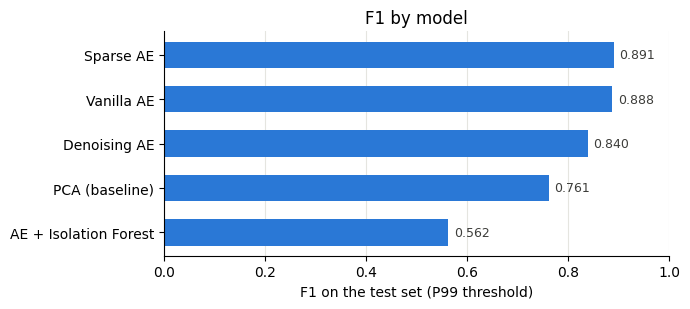

In [7]:
f1_sorted = comparison["F1"].sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(f1_sorted.index, f1_sorted.values, color="#2a78d6", height=0.6)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in f1_sorted.values],
             padding=4, fontsize=9, color="#3d3d3a")
ax.set(xlim=(0, 1), xlabel="F1 on the test set (P99 threshold)", title="F1 by model")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6. Choosing the best model

Our rule: **F1 is the main criterion**, and if two models are close, we look at **PR-AUC** and **false alarms**. The code below takes the model with the highest F1 and then checks the tie-breakers against the second-best model.

In [8]:
ranked = comparison.sort_values("F1", ascending=False)
best, second = ranked.index[0], ranked.index[1]
b, s = ranked.loc[best], ranked.loc[second]

checks = pd.DataFrame({
    best: [b["F1"], b["PR-AUC"], b["False alarms"]],
    second: [s["F1"], s["PR-AUC"], s["False alarms"]],
}, index=["F1", "PR-AUC", "False alarms"])
checks[f"{best} better?"] = [b["F1"] > s["F1"], b["PR-AUC"] > s["PR-AUC"],
                             b["False alarms"] < s["False alarms"]]

BEST_MODEL = best
gap = b["F1"] - s["F1"]
print(f"Best model: {BEST_MODEL} | F1 gap to {second}: {gap:.4f}")
checks

Best model: Sparse AE | F1 gap to Vanilla AE: 0.0029


,Sparse AE,Vanilla AE,Sparse AE better?
F1,0.890945,0.888073,True
PR-AUC,0.904934,0.902630,True
False alarms,0.007632,0.008429,True


**Why I picked the Sparse AE:** it has the highest F1 (0.891), just above the Vanilla AE (0.888). Because the two are so close, I also checked the tie-breakers from our rule, and the Sparse AE is a little better there too: PR-AUC 0.905 vs 0.903, and fewer false alarms (0.76% vs 0.84%). So it wins on all three.

**Its weakness:** the gap is really small. The top autoencoders all land around F1 ≈ 0.89, and my own Sparse AE got only 0.810 in another run where a different L1 value won the tuning, so it isn't clearly better than the Vanilla AE. Also, like every model, it still misses almost all ARP Spoofing (2%) and most MQTT Malformed Data (26%), because in our 40 features these attacks look like normal traffic.

## 7. What we deploy

The deployment (`inference/inference.py` and `demo.ipynb`) uses the saved model file and its metadata: the threshold and the feature names. As a last check, I make sure the threshold saved in the metadata is the same as the one `evaluate()` just computed from the saved model, so the deployed model makes exactly the decisions shown in the table.

In [9]:
MODEL_FILES = {   # models that have both a .keras file and a metadata file
    "Vanilla AE": "dense_ae/vanilla_ae",
    "Sparse AE": "sparse_ae/sparse_ae",
}
assert BEST_MODEL in MODEL_FILES, f"{BEST_MODEL} has no metadata file on GitHub yet"

base = f"{MODELS_DIR}/{MODEL_FILES[BEST_MODEL]}"
meta = json.load(open(f"{base}_metadata.json"))
assert np.isclose(meta["threshold"], results[BEST_MODEL]["threshold"]), "threshold mismatch"

print("Model to deploy:", BEST_MODEL)
print("Model file:     ", f"{base}.keras")
print("Metadata file:  ", f"{base}_metadata.json")
print("Threshold:      ", meta["threshold"])
print("Features:       ", len(meta["features"]))

Model to deploy: Sparse AE
Model file:      iomt-anomaly-detection/models/sparse_ae/sparse_ae.keras
Metadata file:   iomt-anomaly-detection/models/sparse_ae/sparse_ae_metadata.json
Threshold:       0.0001661804503237362
Features:        40
